In [1]:
# Importar librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score
from sklearn.metrics import calinski_harabasz_score

Número de registros: 500
Número de variables: 2


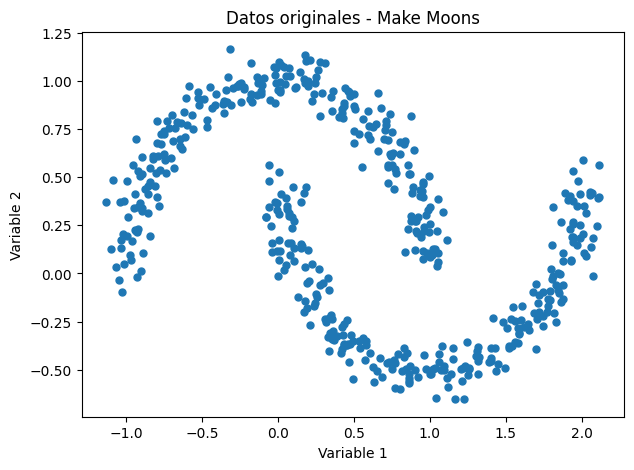

In [2]:
# Generar conjunto de datos
X, y = make_moons(
    n_samples=500,
    noise=0.07,
    random_state=42
)

# Mostrar dimensiones
print("Número de registros:", X.shape[0])
print("Número de variables:", X.shape[1])

# Graficar datos originales
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], s=25)
plt.title("Datos originales - Make Moons")
plt.xlabel("Variable 1")
plt.ylabel("Variable 2")
plt.show()

Estandarizar los datos:

In [3]:
# Estandarizar variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Datos estandarizados correctamente.")

Datos estandarizados correctamente.


Probar diferentes configuraciones de DBSCAN:

In [4]:
# Configuraciones de DBSCAN
configuraciones = [
    (0.15, 5),
    (0.20, 5),
    (0.25, 5),
    (0.30, 5)
]

resultados = []

for eps, min_samples in configuraciones:

    modelo = DBSCAN(eps=eps, min_samples=min_samples)
    etiquetas = modelo.fit_predict(X_scaled)

    clusters = len(set(etiquetas)) - (1 if -1 in etiquetas else 0)
    ruido = list(etiquetas).count(-1)
    porcentaje = (ruido / len(X_scaled)) * 100

    resultados.append([
        eps, min_samples, clusters, ruido, porcentaje
    ])

tabla_dbscan = pd.DataFrame(
    resultados,
    columns=[
        "eps", "min_samples", "Clusters",
        "Puntos de ruido", "Ruido (%)"
    ]
)

print(tabla_dbscan.round(2))

    eps  min_samples  Clusters  Puntos de ruido  Ruido (%)
0  0.15            5         4               17        3.4
1  0.20            5         2                4        0.8
2  0.25            5         2                0        0.0
3  0.30            5         2                0        0.0


La selección será eps = 0.20 y min_samples = 5, esto debido a que:
- Identifica los dos grupos esperados.
- Solamente clasifica 4 observaciones como ruido.
- Conserva el 99.2 % de las observaciones dentro de los clusters.
- Evita unir demasiadas observaciones por utilizar un radio excesivamente grande.


Visualizar los clusters:

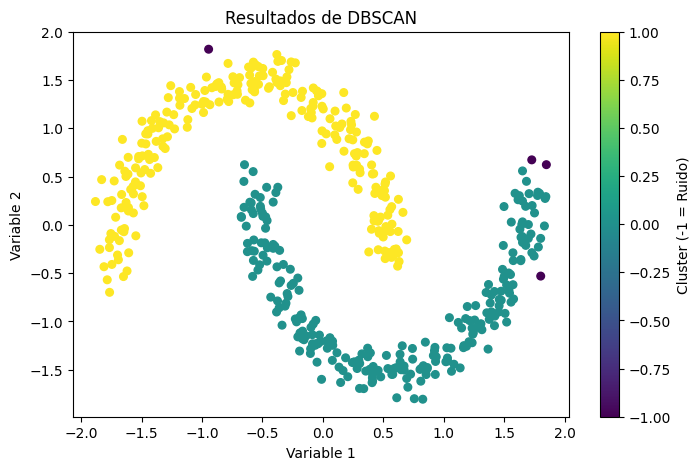

Distribución de clusters:
-1      4
 0    247
 1    249
Name: count, dtype: int64


In [5]:
# Modelo definitivo DBSCAN
dbscan_final = DBSCAN(eps=0.20, min_samples=5)

clusters = dbscan_final.fit_predict(X_scaled)

# Graficar resultados
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap="viridis",
    s=30
)

plt.title("Resultados de DBSCAN")
plt.xlabel("Variable 1")
plt.ylabel("Variable 2")
plt.colorbar(label="Cluster (-1 = Ruido)")
plt.show()

# Mostrar cantidad de puntos por grupo
print("Distribución de clusters:")
print(pd.Series(clusters).value_counts().sort_index())

Calcular las métricas de evaluación:

In [6]:
# Excluir puntos de ruido
mascara = clusters != -1

X_validos = X_scaled[mascara]
clusters_validos = clusters[mascara]

# Calcular métricas si existen al menos dos clusters
if len(np.unique(clusters_validos)) >= 2:

    print("Silhouette Score:",
          silhouette_score(X_validos, clusters_validos))

    print("Davies-Bouldin Index:",
          davies_bouldin_score(X_validos, clusters_validos))

    print("Calinski-Harabasz Score:",
          calinski_harabasz_score(X_validos, clusters_validos))

else:
    print("No existen suficientes clusters para calcular las métricas.")

Silhouette Score: 0.38686391810331966
Davies-Bouldin Index: 1.0178929401108916
Calinski-Harabasz Score: 433.62679580022814
